# Khảo sát dữ liệu UIT-VSFC

Thống kê nhãn, độ dài và bình luận trùng trên các tập gốc. Bảng CSV và biểu đồ PNG, PDF được lưu trong `reports/eda/`.

Nguồn: [UIT NLP trên Hugging Face](https://huggingface.co/datasets/uitnlp/vietnamese_students_feedback).
Nhãn 0 (tiêu cực), 1 (trung tính), 2 (tích cực).


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import re
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'configs/tfidf_lr.yaml').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.datasets.tfidf_data import read_split, sha256_file

OUT = ROOT / 'reports/eda'
OUT.mkdir(parents=True, exist_ok=True)
LABELS = {0: 'Tiêu cực', 1: 'Trung tính', 2: 'Tích cực'}
COLORS = ['#c45154', '#dbb14f', '#308b79']
sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'figure.dpi': 120})
paths = {split: ROOT / f'data/raw/{split}.csv' for split in ['train', 'validation', 'test']}
hashes_before = {split: sha256_file(path) for split, path in paths.items()}
splits = {split: read_split(path) for split, path in paths.items()}
data = pd.concat([frame.assign(split=split) for split, frame in splits.items()], ignore_index=True)
print(f'Python: {sys.executable}')
print(f'Tổng số mẫu: {len(data):,}')
display(pd.DataFrame({'split': list(splits), 'n_samples': [len(f) for f in splits.values()]}))


Python: D:\Tài liệu\GitHub\PMADS\Vietnamese-Sentiment-Analysis\.venv\Scripts\python.exe
Tổng số mẫu: 16,175


,split,n_samples
0,train,11426
1,validation,1583
2,test,3166


## Tổng số mẫu và phân bố nhãn

Trong 16.175 bình luận, có 7.439 tiêu cực (45,99%), 698 trung tính (4,32%) và 8.038 tích cực (49,69%).


,split,label,label_name,count,percent
0,train,0,Tiêu cực,5325,46.60
1,train,1,Trung tính,458,4.01
2,train,2,Tích cực,5643,49.39
3,validation,0,Tiêu cực,705,44.54
4,validation,1,Trung tính,73,4.61
5,validation,2,Tích cực,805,50.85
6,test,0,Tiêu cực,1409,44.50
7,test,1,Trung tính,167,5.27
8,test,2,Tích cực,1590,50.22
9,all,0,Tiêu cực,7439,45.99


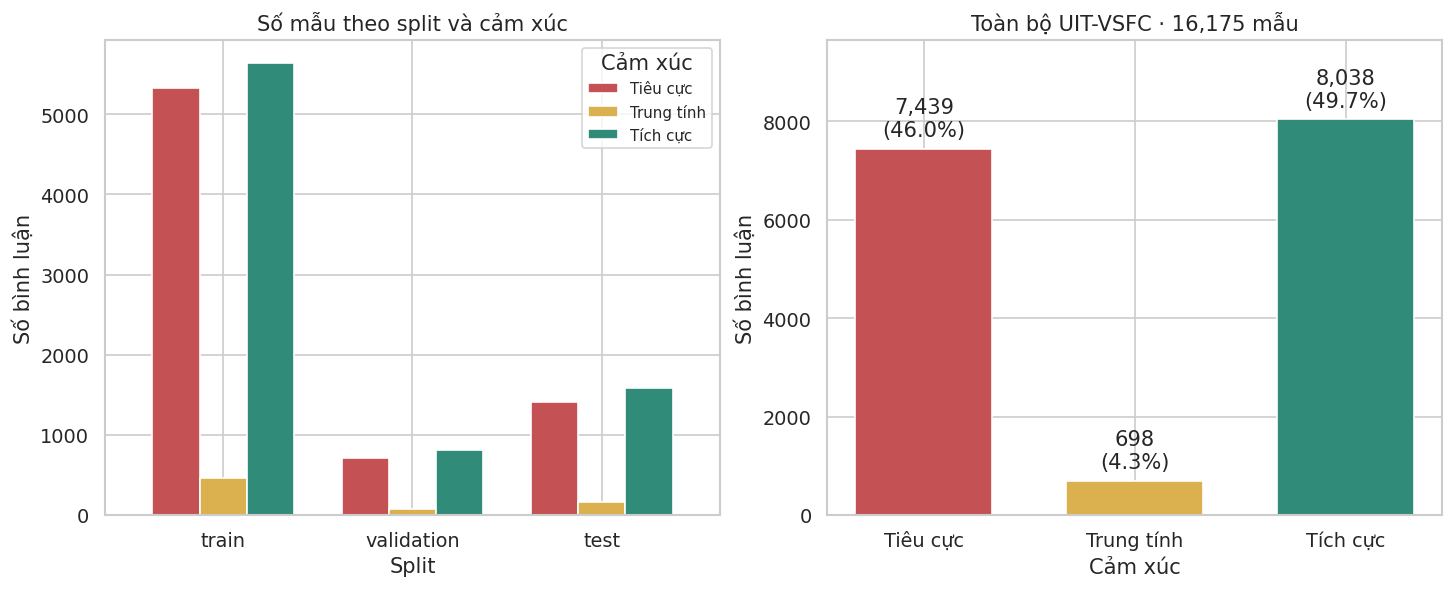

In [2]:
count_rows = []
for split, frame in [*splits.items(), ('all', data)]:
    for label, name in LABELS.items():
        count = int((frame['label'] == label).sum())
        count_rows.append({'split': split, 'label': label, 'label_name': name,
                           'count': count, 'percent': 100 * count / len(frame)})
label_counts = pd.DataFrame(count_rows)
label_counts.to_csv(OUT / 'label_distribution.csv', index=False, encoding='utf-8-sig')
display(label_counts.round(2))

def save_figure(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=300, bbox_inches='tight', facecolor='white')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
by_split = label_counts[label_counts['split'] != 'all'].pivot(index='split', columns='label_name', values='count')
by_split = by_split.reindex(['train', 'validation', 'test'])[[LABELS[i] for i in range(3)]]
by_split.plot.bar(ax=axes[0], color=COLORS, rot=0, width=0.75)
axes[0].set(title='Số mẫu theo split và cảm xúc', xlabel='Split', ylabel='Số bình luận')
axes[0].legend(title='Cảm xúc', fontsize=9)
total = label_counts[label_counts['split'] == 'all']
bars = axes[1].bar(total['label_name'], total['count'], color=COLORS, width=0.65)
axes[1].bar_label(bars, labels=[f'{row.count:,}\n({row.percent:.1f}%)' for row in total.itertuples()], padding=5)
axes[1].set(title=f'Toàn bộ UIT-VSFC · {len(data):,} mẫu', xlabel='Cảm xúc', ylabel='Số bình luận')
axes[1].set_ylim(0, total['count'].max() * 1.20)
save_figure(fig, 'label_distribution')


## Độ dài bình luận

Độ dài trung vị của mỗi tập nằm trong khoảng 45–47 ký tự và 9–10 token. Token được đếm bằng biểu thức `\b\w+\b` trước khi tách từ ghép.

Trên tập test, trung vị là 13 token với bình luận tiêu cực, 8 với tích cực và 7 với trung tính.


n_chars                                                     \
              count   mean    std  min   25%   50%   75%    90%    95%   
split                                                                    
train       11426.0  59.08  43.09  4.0  31.0  47.0  73.0  110.0  141.0   
validation   1583.0  56.36  42.77  4.0  31.0  45.0  69.0  105.8  132.0   
test         3166.0  58.84  44.13  4.0  30.0  46.0  73.0  111.0  147.0   

                    ... n_tokens                                           \
               99%  ...     mean   std  min  25%   50%   75%   90%    95%   
split               ...                                                     
train       218.75  ...    12.68  9.55  1.0  7.0  10.0  16.0  24.0  31.00   
validation  196.18  ...    12.04  9.38  1.0  6.0   9.0  15.0  23.0  29.00   
test        221.35  ...    12.60  9.72  1.0  6.0  10.0  16.0  24.0  31.75   

                          
              99%    max  
split                     
train       48.75  147.0  
validation  43.18  150.0  
test        48.35   93.0  

[3 rows x 22 columns]

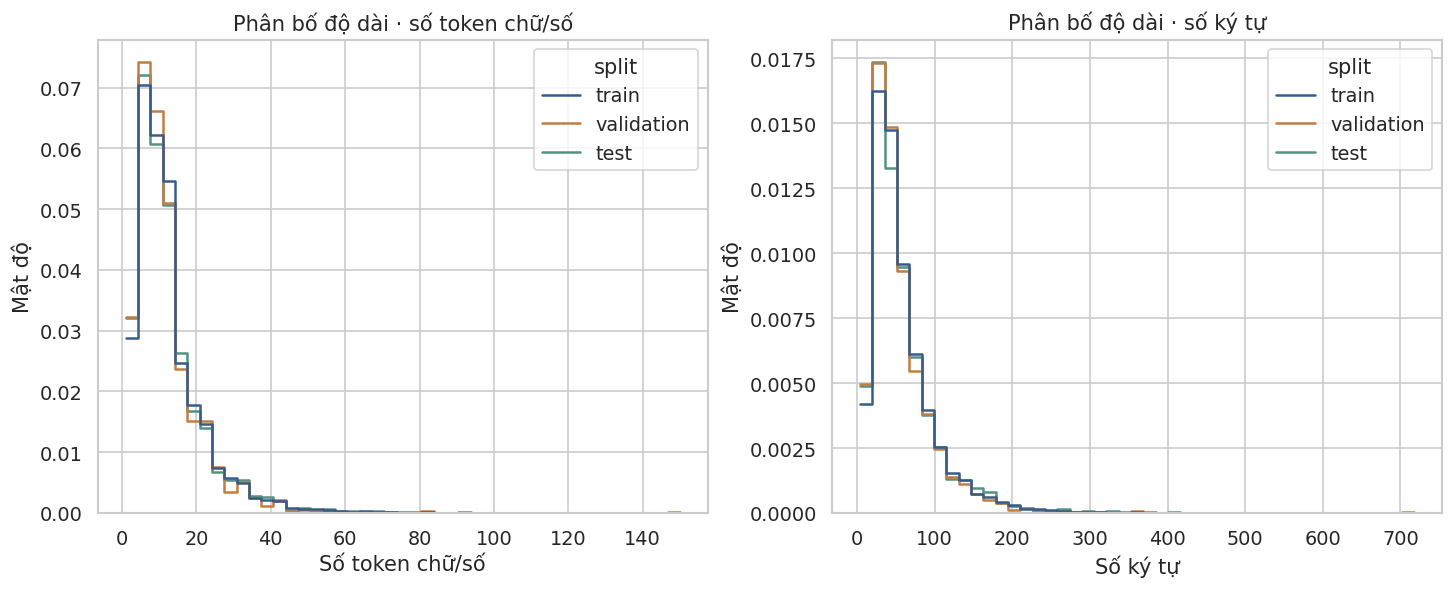

In [3]:
data['n_chars'] = data['text'].str.len()
data['n_tokens'] = data['text'].map(lambda text: len(re.findall(r'\b\w+\b', text, flags=re.UNICODE)))
data['sentiment'] = data['label'].map(LABELS)
length_summary = data.groupby('split', sort=False)[['n_chars', 'n_tokens']].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
length_summary.to_csv(OUT / 'length_summary.csv', encoding='utf-8-sig')
length_by_label = data.groupby(['split', 'label'])[['n_chars', 'n_tokens']].describe()
length_by_label.to_csv(OUT / 'length_by_label.csv', encoding='utf-8-sig')
display(length_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for ax, column, title in zip(axes, ['n_tokens', 'n_chars'], ['Số token chữ/số', 'Số ký tự']):
    sns.histplot(data=data, x=column, hue='split', bins=45, element='step',
                 stat='density', common_norm=False, fill=False,
                 palette=['#375c8c', '#c27d3f', '#529283'], ax=ax)
    ax.set(title=f'Phân bố độ dài · {title.lower()}', xlabel=title, ylabel='Mật độ')
save_figure(fig, 'comment_lengths')


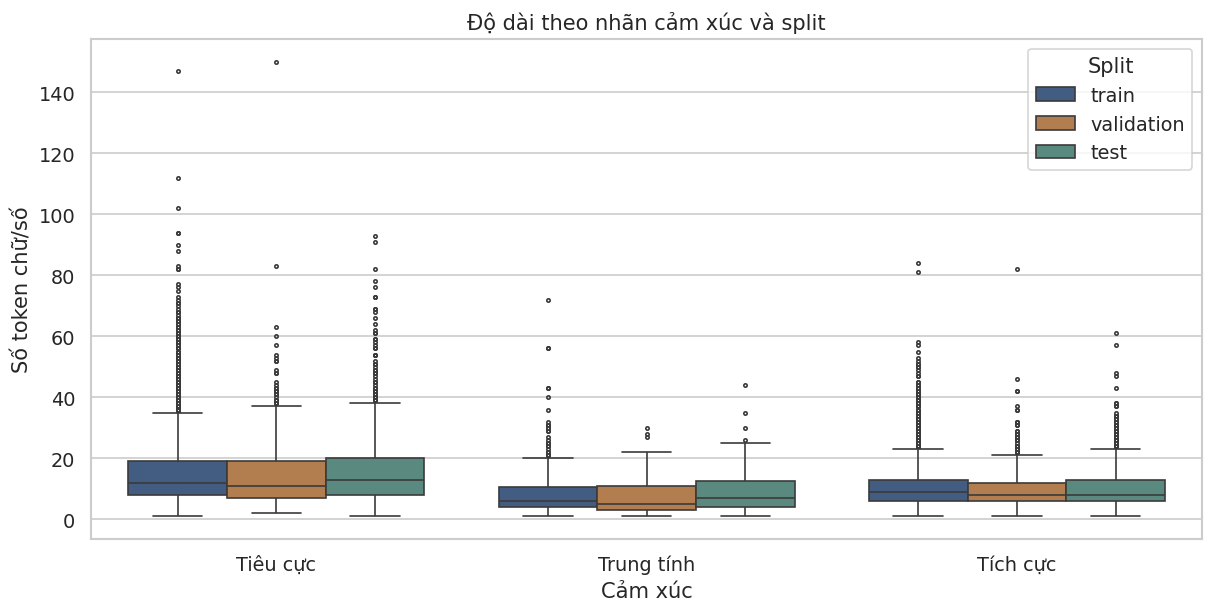

In [4]:
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
sns.boxplot(data=data, x='sentiment', y='n_tokens', hue='split',
            order=[LABELS[i] for i in range(3)],
            palette=['#375c8c', '#c27d3f', '#529283'], fliersize=2, ax=ax)
ax.set(title='Độ dài theo nhãn cảm xúc và split', xlabel='Cảm xúc', ylabel='Số token chữ/số')
ax.legend(title='Split')
save_figure(fig, 'length_by_sentiment')


## Kiểm tra toàn vẹn và các mẫu trùng

Tập train có một bình luận xuất hiện với hai nhãn khác nhau. Khi so sánh nguyên văn, không có bình luận trùng giữa các tập.


In [5]:
integrity = []
for split, frame in splits.items():
    integrity.append({'split': split, 'rows': len(frame),
        'duplicate_text_rows': int(frame.duplicated('text').sum()),
        'duplicate_text_label_rows': int(frame.duplicated(['text', 'label']).sum()),
        'texts_with_conflicting_labels': int((frame.groupby('text')['label'].nunique() > 1).sum())})
integrity = pd.DataFrame(integrity)
integrity.to_csv(OUT / 'integrity_summary.csv', index=False)
display(integrity)
overlap = pd.DataFrame([{'split_a': a, 'split_b': b,
    'shared_unique_texts': len(set(splits[a]['text']) & set(splits[b]['text']))}
    for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]])
overlap.to_csv(OUT / 'split_overlap.csv', index=False)
display(overlap)
assert hashes_before == {split: sha256_file(path) for split, path in paths.items()}, 'Original data changed!'
(OUT / 'data_integrity.json').write_text(json.dumps(
    {'sha256': hashes_before, 'n_samples': len(data), 'columns': ['text', 'label'],
     'label_ids': [0, 1, 2], 'original_data_unchanged': True}, indent=2) + '\n', encoding='utf-8')
print('Dữ liệu gốc không đổi. Đã xuất 3 cặp biểu đồ PNG/PDF và các bảng CSV tại', OUT)


,split,rows,duplicate_text_rows,duplicate_text_label_rows,texts_with_conflicting_labels
0,train,11426,1,0,1
1,validation,1583,0,0,0
2,test,3166,0,0,0


,split_a,split_b,shared_unique_texts
0,train,validation,0
1,train,test,0
2,validation,test,0


Dữ liệu gốc không đổi. Đã xuất 3 cặp biểu đồ PNG/PDF và các bảng CSV tại D:\Tài liệu\GitHub\PMADS\Vietnamese-Sentiment-Analysis\reports\eda


Chạy lại notebook bằng `python -m scripts.execute_eda --repeats 1` từ thư mục gốc.
